# [CS303]Practice 8 - Local Search: Genetic Algorithm
In this practice, you will explore how **Genetic Algorithms (GA)** work and how they can be used to search for good solutions in large, complex spaces.

You will first experiment with a **toy problem** — generating a target phrase — and then apply the same idea to solve the **N-Queens problem**.

#### **Practice Deadline and Checking Policy**

The score for this practice is determined by **when you have your work checked during your lab session**. Please follow the schedule of your own lab group.

| Lab Group     | Full Credit (100%)           | Late Check (50%)        | After the 50% Deadline |
| ------------- | ---------------------------- | ----------------------- | ---------------------- |
| **Wednesday** | **Nov. 04** or **Nov. 11**   | **Nov. 18**             | 0%                     |
| **Thursday**  | **Nov. 05** or **Nov. 12**   | **Nov. 19**             | 0%                     |
| **Friday**    | **Nov. 06** or **Nov. 13**   | **Nov. 20**             | 0%                     |

You have **two lab sessions to complete and have your work checked for full credit (100%)**. If you miss both sessions, you can still have your work checked at the designated late-check session, but you will receive only **50% of the points**. Any check after the 50% deadline will receive **0 points**.

**Important:** The score is determined by the **date of your in-person check**.

**Evaluation Criteria**

Your submission will be assessed on:

* Clear understanding of every line of your code (no blind copy-paste).
* Successful compilation of the program.
* Correctness of the program logic.
* Reasonable efficiency of the solution.



In [1]:
%load_ext autoreload
%autoreload 2
import random
import numpy as np
import matplotlib.pyplot as plt
from utils import plot_NQueens, plot_evolution

## 1. Generating Phrases

Let’s begin with a simple but fun example: evolving random strings until one of them matches a **target phrase** (e.g., `"Genetic Algorithm"`).
Assume the length of the target phrase is known.

### Problem Formulation

1. **Representation:** Each individual is a string.
2. **Search Space:**  $m^l$ where $m$ is the size of the alphabet (set of characters in our interest) and $l$ is the length of the string.

### Designing a Genetic Algorithm

1. **Chromosome:** The string itself.
2. **Fitness Function:** Measures how close a string is to the target phrase (e.g., number of matching characters).
3. **Crossover (Mating):** Combines two parent strings to produce a new string.
4. **Mutation:** Randomly changes a few characters to maintain diversity in the population.

The following cells will guide you through the process step by step. Complete the `TODO` sections in the provided code so the program runs correctly — this will show how a GA gradually evolves a population toward the target phrase.


In [2]:
# setting up the problem
target = 'Genetic Algorithm'
u_case = [chr(x) for x in range(65, 91)]
l_case = [chr(x) for x in range(97, 123)]
gene_pool = u_case + l_case + [' '] # all English chracters and white space

def init_population(pop_size, gene_pool, state_length):
    """
    Randomly initialize a population for genetic algorithm
        pop_size  :  Number of individuals in population
        gene_pool   :  List of possible values for individuals
        state_length:  The length of each individual
    """

    population = []
    for _ in range(pop_size):
        new_individual = "".join(random.choices(gene_pool, k=state_length))
        population.append(new_individual)

    return population

# test
init_pop = init_population(10, gene_pool, len(target))
init_pop

['GgSIZstlgSCGbOQZH',
 'svTobUsSCON JsaTX',
 'EVBFQcymWiTUtKeBj',
 'kLbHCDPUVDFXhjnOz',
 'hcnkMToXzLMxPRBjK',
 'yPDleWpiiGZXPrWfn',
 'rXXbPtwvUGuuYmsms',
 'LSXHqaKZFSbnqabsv',
 'qxXiZvtewcYNdqFlH',
 'yDvfuujMIikPEMPyx']

In [3]:
def fitness_fn(sample):
    # TODO: evaluate how close *sample* is to the target, e.g., number of matching characters
    
    # for instance:
    # target = "ABC", sample = "ADC"
    # 0: A == A -> match
    # 1: D != B -> no match
    # 2: c == c -> match
    # in total, 2 matches, so fitness = 2
    return sum(
        candidate_char == target_char
        for candidate_char, target_char in zip(sample, target)
    )

# test
fitness_fn(init_pop[0])

1

In [4]:
def select(r, population, fitness_fn):
    """
    TODO: select *r* samples from *population*
    the simplest choice is to sample from *population* with each individual weighted by its fitness
    """

    # parameters:
    # r: number of samples to select
    # population: list of individuals
    # fitness_fn: function to evaluate the fitness of an individual

    # compute the fitness of each individual in the population,
    # as a list of weights for sampling
    weights = [fitness_fn(individual) for individual in population]

    # if all weights are zero -> any(weights) == False
    # if only some weights are zero -> any(weights) == True
    # so if all weights are zero, we cannot sample with weights, so we need to handle this case
    if not any(weights):
        return random.choices(population, k=r)

    # if we reach this point, it means that at least one individual has a non-zero fitness
    # allow sampling with replacement, with each individual weighted by its fitness
    return random.choices(population, weights=weights, k=r)


# test
parents = select(2, init_pop, fitness_fn)
parents

['GgSIZstlgSCGbOQZH', 'hcnkMToXzLMxPRBjK']

In [5]:
def recombine(x, y):
    """
    TODO: combine two parents to produce an offspring
    """

    # parameters:
    # x: first psarent
    # y: second parent

    # for instance:
    # x = "ABC", y = "XYZ"
    # we can choose a random crossover point, e.g., 1
    # then the offspring will be "AYZ" (first part from x, second part from y)
    # or we can choose a random crossover point, e.g., 2
    # then the offspring will be "ABZ" (first part from x, second part from y)
    # or we can choose a random crossover point, e.g., 0
    # then the offspring will be "XYZ" (first part from x, second part from y)
    # or we can choose a random crossover point, e.g., 3
    # then the offspring will be "ABC" (first part from x, second part from y)
    # so the crossover point can be any index from 0 to len(x) (or len(y), since they should be the same length)

    # if the length of the parents is not the same,
    # we cannot recombine them, so we raise an error
    if len(x) != len(y):
        raise ValueError("Parents must have the same length")

    # if the length of the parents is less than 2,
    # that is 0 or 1, then no crossover can happen,
    # we cannot recombine them, so we return one of the parents (e.g., x)
    if len(x) < 2:
        return x

    # the crossover point must be within the range of the length of the parents,
    # so we choose a random index from 1 to len(x) - 1
    cut = random.randrange(1, len(x))

    # return the offspring by combining the first part of x and the second part of y
    return x[:cut] + y[cut:]

def mutate(x, gene_pool, pmut):
    """
    apply mutation to *x* by randomly replacing one of its gene from *gene_pool*
    """
    if random.uniform(0, 1) >= pmut:
        return x

    n = len(x)
    g = len(gene_pool)
    c = random.randrange(0, n)
    r = random.randrange(0, g)

    new_gene = gene_pool[r]
    # Strings are immutable, so reconstruct them with slicing.
    if isinstance(x, str):
        return x[:c] + new_gene + x[c + 1:]

    # N-Queens individuals are lists; copy before changing one gene
    # so the parent in the current population remains unchanged.
    child = x.copy()
    child[c] = new_gene
    return child

# test
child = mutate(recombine(*parents), gene_pool, 0.1)
child

'GgSIZstlgSCGbOQjK'

In [6]:
# now refactor things into a *Problem* abstraction
# you can directly reuse what you have implemented above
from abc import ABC, abstractmethod

class GAProblem(ABC):
    @abstractmethod
    def init_population(self, pop_size): pass

    @abstractmethod
    def fitness(self, sample): pass

    @abstractmethod
    def reproduce(self, population): pass

    @abstractmethod
    def replacement(self, old, new): pass

class PhraseGeneration(GAProblem):
    def __init__(self, target, alphabet):
        self.target = target
        self.alphabet = alphabet
        self.max_fitness = len(target)

    def init_population(self, pop_size):
        # raise NotImplementedError()
        return init_population(pop_size, self.alphabet, len(self.target))

    def fitness(self, sample):
        # TODO: evaluate how close *sample* is to the target
        
        return sum(
            candidate_char == target_char
            for candidate_char, target_char in zip(sample, self.target)
        )
    
    def reproduce(self, population, mutation_rate):
        """
        TODO: generate the next generation of population

        hint: make a new individual with 
        
        mutate(recombine(*select(2, population, fitness_fn)), gene_pool, pmut)

        """

        # the procedure of reproduction is as follows:
        # 1. select two parents from the population, with each individual weighted by its fitness
        # 2. recombine the two parents to produce an offspring
        # 3. mutate the offspring with a given mutation rate

        next_generation = []

        # the for loop below will generate the next generation of population
        for _ in population:
            # select two parents
            # the probability is proportional to their fitness
            # can two parents be the same? yes, it is possible, but it is unlikely if the population is large enough
            parent_x, parent_y = select(
                2,
                population,
                self.fitness
            )

            # recombine the two parents to produce an offspring
            # we have already implemented the recombine function above
            child = recombine(parent_x, parent_y)

            # mutate the offspring with a given mutation rate
            # we have already implemented the mutate function above
            child = mutate(
                child,
                self.alphabet, # the gene pool is the alphabet
                mutation_rate # the mutation rate is the probability of mutation
            )

            # add the child to the next generation
            next_generation.append(child)

        # after we have generated the next generation, we return it
        return next_generation
    
    def replacement(self, old, new):
        """
        You can use your own strategy, for example retain some solutions from the old population
        """
        return new

def genetic_algorithm(
        problem: GAProblem, 
        ngen, n_init_size, mutation_rate, 
        log_intervel=100
    ):

    population = problem.init_population(n_init_size)
    best = max(population, key=problem.fitness)
    history = [(0, list(map(problem.fitness, population)))]

    for gen in range(ngen):
        next_gen    = problem.reproduce(population, mutation_rate)
        population  = problem.replacement(population, next_gen)

        if gen % log_intervel == 0:
            current_best = max(population, key=problem.fitness)
            if problem.fitness(current_best) > problem.fitness(best): best = current_best
            print(f"Generation: {gen}/{ngen},\tBest: {best},\tFitness={problem.fitness(best)}")         
            history.append((gen, list(map(problem.fitness, population))))
    
    history.append((ngen-1, list(map(problem.fitness, population))))
    return best, history

In [7]:
# now set up the parameters
ngen = 1200
max_population = 120
mutation_rate = 0.08

sid = 12412307 #TODO:  replace this with your own sid

target = f"Genetic Algorithm by {sid}"

alphabet = sorted(set(target)) # TODO: fix this: what is the search space now?
# the search space is now the set of unique characters in the target string,
# which includes uppercase letters, lowercase letters, and spaces.

problem = PhraseGeneration(target, alphabet)

# and run it
solution, history = genetic_algorithm(problem, ngen, max_population, mutation_rate)
solution

Generation: 0/1200,	Best: 0e7eoiGc03m20bh3g4bgtA371l2lG,	Fitness=5
Generation: 100/1200,	Best: Genetim A3gorloh4 07 1r4ml30G,	Fitness=18
Generation: 200/1200,	Best: Genetim A gorl3h4 0y 1h4mg30G,	Fitness=19
Generation: 300/1200,	Best: Genetim A gorl3h4 0y 1h4mg30G,	Fitness=19
Generation: 400/1200,	Best: Genetio A7gorinh4 0y 124e230l,	Fitness=22
Generation: 500/1200,	Best: Genetic A7gorm3hm by 124m2307,	Fitness=25
Generation: 600/1200,	Best: Genetic A7gorm3hm by 124m2307,	Fitness=25
Generation: 700/1200,	Best: Genetic A7gorm3hm by 124m2307,	Fitness=25
Generation: 800/1200,	Best: Genetic A7gorithm by 124m2307,	Fitness=27
Generation: 900/1200,	Best: Genetic A7gorithm by 12412307,	Fitness=28
Generation: 1000/1200,	Best: Genetic A7gorithm by 12412307,	Fitness=28
Generation: 1100/1200,	Best: Genetic A7gorithm by 12412307,	Fitness=28


'Genetic A7gorithm by 12412307'

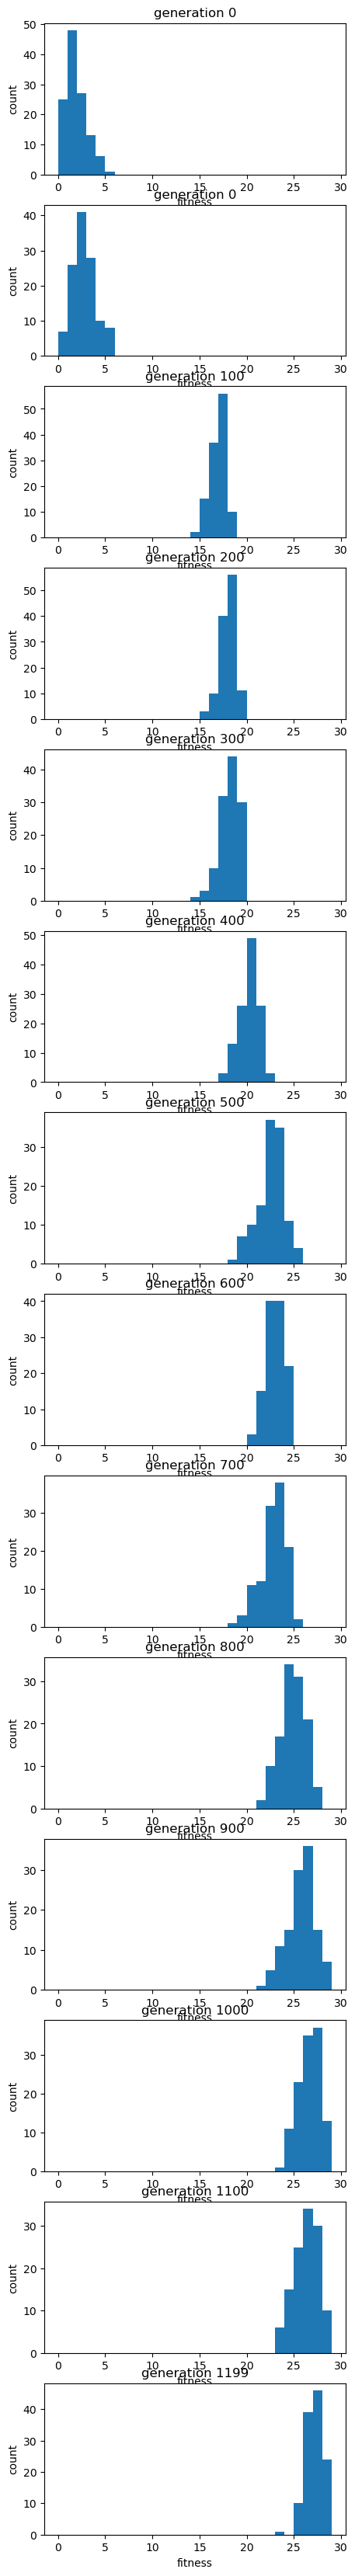

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
       13., 14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25.,
       26., 27., 28., 29.])

In [8]:
# visualize the evolution of the polulation
bins = np.linspace(0, problem.max_fitness, problem.max_fitness+1)
plot_evolution(history, bins)
bins

## 2. N-Queens Problem

Next, we will apply the genetic algorithm to the classic **N-Queens problem**.

### Problem Formulation

1. **Representation:** The board configuration, typically represented as an array indicating queen positions.
2. **Search Space:** $n^n$, if no constraints are applied.

### Modifying the GA

To adapt GA for this problem:

* The **fitness function** should measure how many pairs of queens are not attacking each other — the goal is to **maxmize** this value.
* Other parts (representation, crossover, mutation) can remain mostly the same as in the previous example.

By comparing the two problems, you’ll see how GAs can be adapted to very different types of search spaces.


In [9]:
class NQueensProblem(GAProblem):
    def __init__(self, n):
        self.n = n
        self.max_fitness =  n*(n-1)//2 # max number if non-attacking pairs

    def init_population(self, pop_size):
        # TODO:alomost the same as the previous problem.
        
        # use a list of integers from 0 to n-1 to represent the positions of the queens
        # index i: the column of the queen
        # value at index i: the row of the queen
        # for example, for n=4, a possible individual is [1, 3, 0, 2], which means:
        # the queen in column 0 is in row 1,
        # the queen in column 1 is in row 3,
        # the queen in column 2 is in row 0,
        # the queen in column 3 is in row 2,
        # this representation ensures that no two queens are in the same column,
        # and we can easily check for attacks in rows and diagonals.

        return [
            random.choices(range(self.n), k=self.n)
            for _ in range(pop_size)
        ]
    
    def fitness(self, queens):
        """
        TODO

        hint: count the non-attacking pairs
        """

        # compute the number of non-attacking pairs of queens
        # two queens are non-attacking if:
        # 1. they are not in the same row
        # 2. they are not in the same diagonal
        # since index i represents the column of the queen,
        # there is no need to check for attacks in columns,
        # as they are bound to be in different columns by definition of the representation.

        non_attacking_pairs = 0

        for i in range(self.n):
            for j in range(i + 1, self.n):
                # not in the same row
                different_rows = queens[i] != queens[j]

                # not in the same diagonal
                different_diagonals = abs(queens[i] - queens[j]) != abs(i - j)

                # if both conditions are satisfied (not the same row & not the same diagonal),
                # then we have a non-attacking pair of queens
                if different_rows and different_diagonals:
                    non_attacking_pairs += 1

        return non_attacking_pairs

    def reproduce(self, population, mutation_rate):
        # TODO:alomost the same as the previous problem.
        
        # use the same procedure as in the PhraseGeneration problem,
        # but with the NQueens representation.

        # the gene pool is now the set of integers from 0 to n-1,
        # representing the possible rows for each queen in a given column.

        next_generation = []

        for _ in population:
            # select two parents
            parent_x, parent_y = select(
                2,
                population,
                self.fitness
            )

            # recombine the two parents to produce an offspring
            child = recombine(parent_x, parent_y)

            # mutate the offspring with a given mutation rate
            child = mutate(
                child,
                list(range(self.n)),
                mutation_rate
            )

            next_generation.append(child)

        return next_generation

    def replacement(self, old, new):
        """
        You can use your own strategy, for example retain some solutions from the old population
        """
        return new

    def __repr__(self):
        return f"{self.n}-Queens Problem"

In [10]:
from utils import plot_NQueens
ngen = 1000
init_size = 120
mutation_rate = 0.08

n = 8
problem = NQueensProblem(n)
solution, history = genetic_algorithm(problem, ngen, init_size, mutation_rate)

Generation: 0/1000,	Best: [6, 3, 7, 2, 0, 6, 1, 7],	Fitness=25
Generation: 100/1000,	Best: [2, 0, 3, 6, 7, 1, 4, 7],	Fitness=26
Generation: 200/1000,	Best: [2, 0, 3, 7, 5, 1, 6, 4],	Fitness=27
Generation: 300/1000,	Best: [2, 0, 3, 7, 5, 1, 6, 4],	Fitness=27
Generation: 400/1000,	Best: [2, 0, 3, 7, 5, 1, 6, 4],	Fitness=27
Generation: 500/1000,	Best: [2, 0, 3, 7, 5, 1, 6, 4],	Fitness=27
Generation: 600/1000,	Best: [2, 0, 3, 7, 5, 1, 6, 4],	Fitness=27
Generation: 700/1000,	Best: [2, 0, 3, 7, 5, 1, 6, 4],	Fitness=27
Generation: 800/1000,	Best: [2, 0, 3, 7, 5, 1, 6, 4],	Fitness=27
Generation: 900/1000,	Best: [2, 6, 1, 7, 5, 3, 0, 4],	Fitness=28


/Users/justinfan7777777/Coding/Labs/Artificial Intelligence/practice8/utils.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


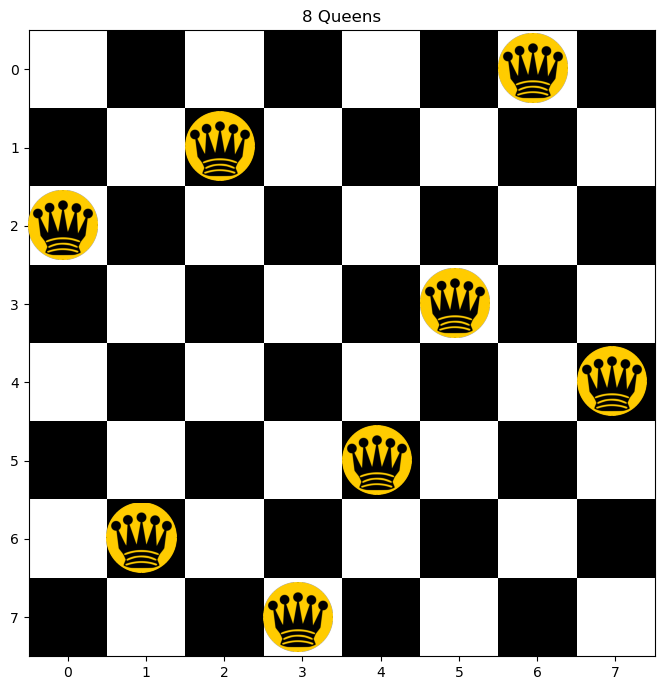

In [11]:
# Example of how to use this function
# plot_NQueens([4, 2, 0, 6, 1, 7, 5, 3])
# replace the parameter with your own results
plot_NQueens(solution)

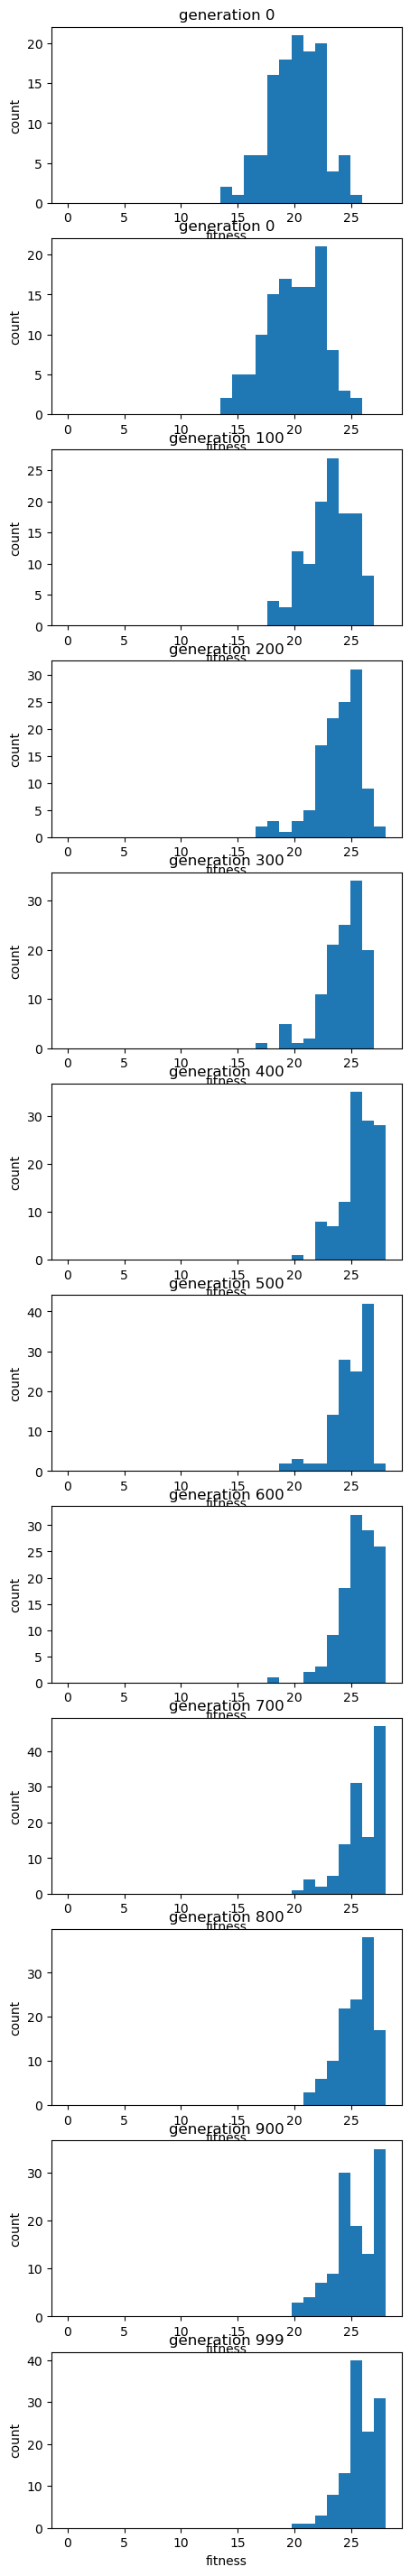

In [12]:
# Visualize the evolution of the polulation
bins = np.linspace(0, problem.max_fitness, problem.max_fitness)
plot_evolution(history, bins)